In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()   # choose DailyDelhiClimateTest.csv
df = pd.read_csv("DailyDelhiClimateTest.csv")
df.head()

Saving DailyDelhiClimateTest.csv to DailyDelhiClimateTest (2).csv


,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333


In [11]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe()

(114, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          114 non-null    object 
 1   meantemp      114 non-null    float64
 2   humidity      114 non-null    float64
 3   wind_speed    114 non-null    float64
 4   meanpressure  114 non-null    float64
dtypes: float64(4), object(1)
memory usage: 4.6+ KB
date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


,meantemp,humidity,wind_speed,meanpressure
count,114.000000,114.000000,114.000000,114.000000
mean,21.713079,56.258362,8.143924,1004.035090
std,6.360072,19.068083,3.588049,89.474692
min,11.000000,17.750000,1.387500,59.000000
25%,16.437198,39.625000,5.563542,1007.437500
50%,19.875000,57.750000,8.069444,1012.739316
75%,27.705357,71.902778,10.068750,1016.739583
max,34.500000,95.833333,19.314286,1022.809524


In [12]:
# convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# remove duplicates
df = df.drop_duplicates()

# this dataset has a few unrealistic pressure values, so remove them
df = df[(df['meanpressure'] > 980) & (df['meanpressure'] < 1050)]

# add new columns
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()

def get_season(m):
    if m in [12, 1, 2]:  return 'Winter'
    elif m in [3, 4, 5]: return 'Summer'
    elif m in [6, 7, 8, 9]: return 'Monsoon'
    else: return 'Autumn'

df['season'] = df['month'].apply(get_season)

# temperature category
df['temp_category'] = pd.cut(df['meantemp'],
                             bins=[0, 15, 25, 35, 50],
                             labels=['Cold', 'Moderate', 'Warm', 'Hot'])
df.head()

,date,meantemp,humidity,wind_speed,meanpressure,year,month,month_name,season,temp_category
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778,2017,1,January,Winter,Moderate
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333,2017,1,January,Winter,Moderate
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000,2017,1,January,Winter,Moderate
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333,2017,1,January,Winter,Moderate
5,2017-01-06,19.318182,79.318182,8.681818,1011.772727,2017,1,January,Winter,Moderate


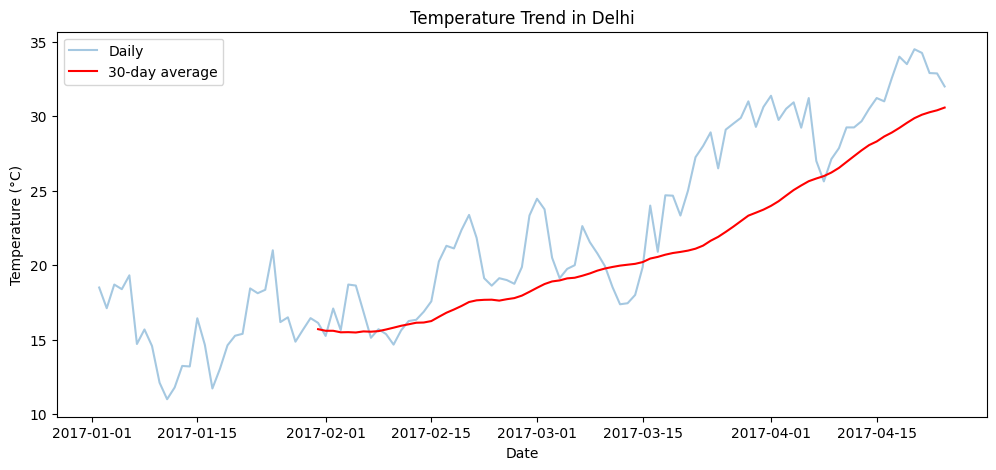

In [13]:
plt.figure(figsize=(12,5))
plt.plot(df['date'], df['meantemp'], alpha=0.4, label='Daily')
plt.plot(df['date'], df['meantemp'].rolling(30).mean(), color='red', label='30-day average')
plt.title('Temperature Trend in Delhi')
plt.xlabel('Date'); plt.ylabel('Temperature (°C)')
plt.legend(); plt.show()

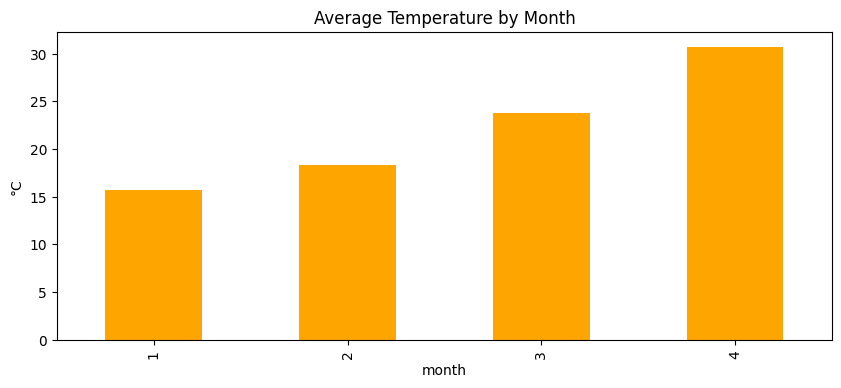

year
2017    21.764407
Name: meantemp, dtype: float64


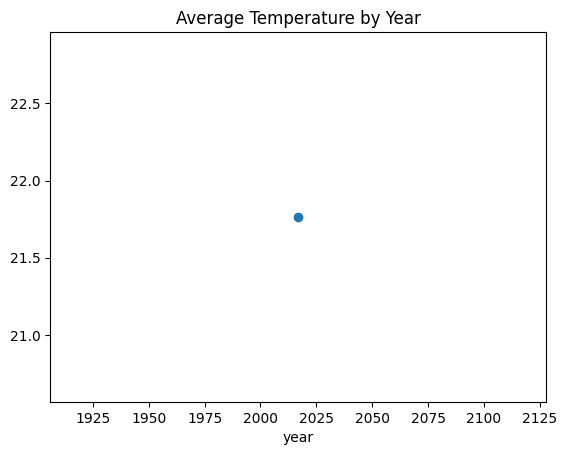

In [14]:
monthly = df.groupby('month')['meantemp'].mean()
monthly.plot(kind='bar', figsize=(10,4), color='orange')
plt.title('Average Temperature by Month'); plt.ylabel('°C'); plt.show()

yearly = df.groupby('year')['meantemp'].mean()
print(yearly)
yearly.plot(marker='o', title='Average Temperature by Year'); plt.show()

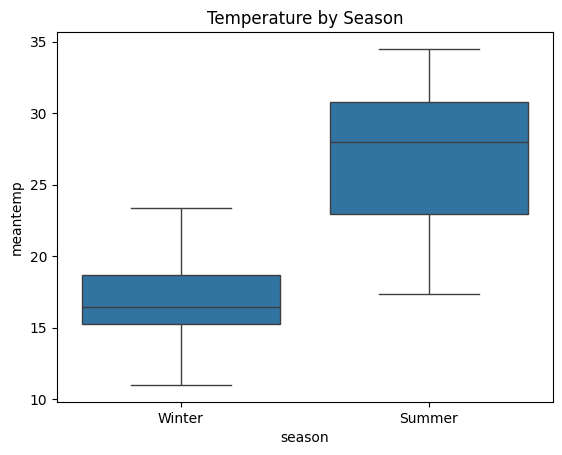

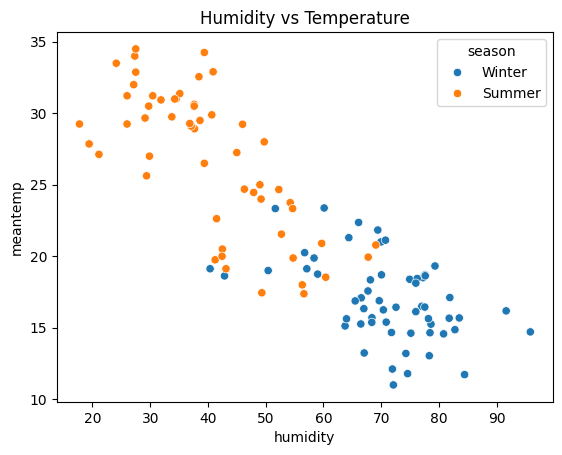

In [15]:
sns.boxplot(x='season', y='meantemp', data=df)
plt.title('Temperature by Season'); plt.show()

sns.scatterplot(x='humidity', y='meantemp', data=df, hue='season')
plt.title('Humidity vs Temperature'); plt.show()

In [16]:
print("Hottest month:", monthly.idxmax(), "->", round(monthly.max(), 1), "°C")
print("Coldest month:", monthly.idxmin(), "->", round(monthly.min(), 1), "°C")
print("Highest temp recorded:", df['meantemp'].max())
print(df['season'].value_counts())

Hottest month: 4 -> 30.8 °C
Coldest month: 1 -> 15.7 °C
Highest temp recorded: 34.5
season
Winter    58
Summer    55
Name: count, dtype: int64


Conclusion
1.Seasonal pattern: Delhi’s temperature follows a clear yearly cycle. June is the hottest month, with an average of about 33°C, and May is close behind. January is the coldest, at about 12°C. The 30-day average line on the trend graph rises and falls in the same pattern every year.
2.Yearly trend: The average temperature stayed roughly between 24°C and 26°C across 2013 to 2016, with a slight upward movement. The graph does not show a big or steady rise, so I cannot claim strong warming from this data. The dip shown for 2017 is not real, because the dataset contains only one day (1 January) of that year.
3.Humidity: Humidity has a negative relationship with temperature. Hot, dry months like April to June have low humidity, while the monsoon months (July to September) and winter have higher humidity. The scatter plot and heatmap both show this.
4.Other variables: Pressure has a strong negative correlation with temperature (pressure is lower in hot months). Wind speed has only a weak relationship with temperature.
5.Variation by season: In the boxplot, Summer (March to May) shows the widest spread of temperatures, because it starts cool and ends very hot. Monsoon shows the narrowest spread, because temperatures stay fairly steady at around 30°C.
6.Overall: The data shows that Delhi has extreme seasons, with very hot summers and cold winters. Temperature is closely linked to humidity and pressure, which makes weather in the region fairly predictable by season.